# Практикум 1, часть 3. Задания вживую

Курс «От интеллектуального поиска к интеллектуальным агентам», ВМК МГУ.

**Что мы делаем и зачем.** Задания 1 и 2 строят две части ассистента для вашей области: корпус с графом связей и онтологию с машиной вывода. Чтобы маршрут был виден целиком, в этом блокноте оба задания выполнены на маленькой области из 12 записей: **правила зачёта** по учебному курсу и ведомость пяти студентов. Правила вымышленные и к правилам нашего курса отношения не имеют. Область устроена так же, как задача редактора: требования, термины, зависимости, журнал.

Всё, что здесь показано, лежит в папке `starter/`. Это готовый маленький репозиторий. Своё задание выполняется на своей области и на корпусе не меньше 30 записей.

| Шаг | Задание | Что делаем | Файл |
|---|---|---|---|
| 1 | задание 1 | корпус утверждений | `kg/corpus.csv` |
| 2 | задание 1 | граф и карта знаний | `kg/MAP.md` |
| 3 | задание 1 | пять вопросов исследователя | `README.md` |
| 4 | задание 1 | проверка скриптом | `scripts/check_hw1.py` |
| 5 | задание 2 | шесть решений от карты к онтологии | бумага |
| 6 | задание 2 | классы, свойства, ограничения, индивиды | `kg/ontology.ttl` |
| 7 | задание 2 | выведенный факт | `kg/ONTOLOGY.md` |
| 8 | задание 2 | намеренное противоречие | `kg/ONTOLOGY.md` |
| 9 | задание 2 | проверка скриптом | `scripts/check_l2.py` |
| 10 | цель | агент над своим корпусом | `src/agent_my.py` |

In [1]:
import os, sys, subprocess, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) != "starter":
    sys.path.insert(0, os.getcwd())            # viz лежит в папке занятия
    sys.path.insert(0, os.path.join(os.getcwd(), "agent"))   # ядро агента и llm_local лежат в agent/
    os.chdir("starter")                        # работаем в корне маленького репозитория
sys.path.insert(0, "src")
import pandas as pd
import viz
from llm_local import pick_llm, run_live_or_record

pd.set_option("display.max_colwidth", 95); pd.set_option("display.width", 170)
LLM, note = pick_llm()
print("модель:", note)
if LLM: print("ответ модели может занимать до минуты на процессоре; предел ожидания задаёт LLM_TIMEOUT")
print("папка:", os.path.basename(os.getcwd()), "| файлы:", sorted(os.listdir(".")))

модель: Ollama не отвечает или моделей нет: показываем записи, инструменты работают по-настоящему
папка: starter | файлы: ['.claude', 'AGENTS.md', 'CLAUDE.md', 'README.md', 'diary.md', 'kg', 'scripts', 'src']


# Задание 1

## Шаг 1. Корпус

Корпус есть таблица утверждений области. Шесть столбцов: `id`, `тип`, `название`, `формулировка`, `зависит_от`, `источник`. Главный столбец `зависит_от`: в нём через точку с запятой перечислены записи, на которые утверждение опирается прямо.

In [2]:
corpus = pd.read_csv("kg/corpus.csv", dtype=str).fillna("")
corpus[["id", "тип", "название", "зависит_от", "источник"]]

,id,тип,название,зависит_от,источник
0,S1,Раздел,Раздел 1. Общие положения,,Правила зачёта §1
1,S2,Раздел,Раздел 2. Термины,S1,Правила зачёта §2
2,S3,Раздел,Раздел 3. Порядок зачёта,S1,Правила зачёта §3
3,T1,Термин,Студент,S2,Правила зачёта §2.1
4,T2,Термин,Задание,S2,Правила зачёта §2.2
5,T3,Термин,Срок сдачи,S2;T2,Правила зачёта §2.3
6,T4,Термин,Балл,S2;T2,Правила зачёта §2.4
7,T5,Термин,Зачёт,S2;T4,Правила зачёта §2.5
8,R31,Требование,3.1 Число заданий,S3;T1;T2,Правила зачёта §3.1
9,R32,Требование,3.2 Срок,S3;T3,Правила зачёта §3.2


Как появляется строка корпуса. Берём фразу документа: «Зачёт выставляется студенту при выполнении требований 3.1, 3.2 и 3.3». Спрашиваем: на что она ссылается? На три требования, на термин «Зачёт» и на свой раздел. Записываем `S3;T5;R31;R32;R33`.

Рядом лежат данные, по которым требования проверяются: ведомость.

In [3]:
vedomost = pd.read_csv("kg/data/vedomost.csv", dtype=str).fillna("")
vedomost.pivot(index="студент", columns="задание", values="балл").replace("", "—")

задание,зад1,зад2,зад3,зад4
студент,,,,
Аня,22,20,18,21
Боря,20,21,22,—
Вика,24,23,25,20
Гоша,23,22,—,—
Даша,15,18,20,—


## Шаг 2. Граф и карта знаний

Столбец `зависит_от` превращает таблицу в граф.

**Прогноз.** У требования 3.4 записано пять зависимостей. На сколько положений оно опирается с учётом цепочек?

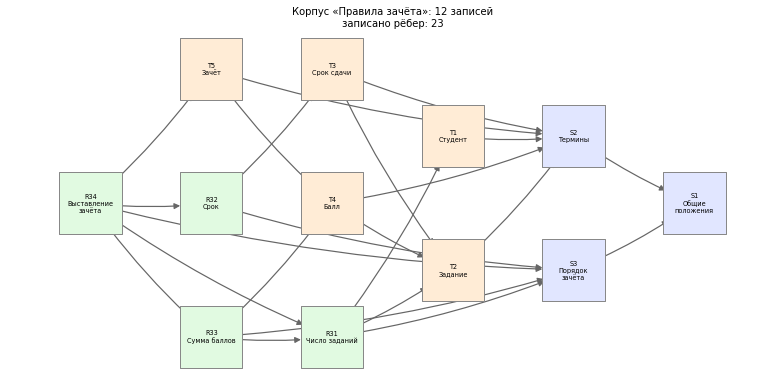

In [4]:
_ = viz.draw_deps(corpus, title="Корпус «Правила зачёта»: 12 записей", figsize=(11, 5.4))

In [5]:
import agent_my as m            # инструменты агента стартового набора
deps = m.graph_deps("R34")
print(len(deps["опирается_на"]), "положений:", ", ".join(x.split()[0] for x in deps["опирается_на"]))

11 положений: R31, R32, R33, S1, S2, S3, T1, T2, T3, T4, T5


Карта знаний (`kg/MAP.md`) рисует типы: какие виды сущностей есть в области и какими видами связей они соединены. В нашей области три вида положений, студент и сдача, связи `зависит_от` и `автор`.

## Шаг 3. Пять вопросов исследователя

У каждого вопроса есть ожидаемый ответ и источник. Обязательны три типа: факт, зависимость, смысл.

In [6]:
readme = open("README.md", encoding="utf-8").read()
print("\n".join(l for l in readme.splitlines() if l.startswith("| ") and ("Тип" in l or l[2].isdigit())))

| № | Тип | Вопрос | Ожидаемый ответ | Источник |
| 1 | (1) факт | Сколько заданий нужно сдать для зачёта? | не менее трёх | R31, Правила зачёта §3.1 |
| 2 | (2) зависимость | На какие положения опирается требование 3.4 о выставлении зачёта? | на 11 положений: R31, R32, R33, S1, S2, S3, T1–T5 | R34 и цепочки `зависит_от` |
| 3 | (3) смысл | Есть ли в правилах норма об опоздании, если слова «опоздание» в тексте нет? | да, требование 3.2 о сроке сдачи | R32, T3 |
| 4 | (4) проверка | Кто из студентов получает зачёт? | Аня и Боря | ведомость и требования R31–R33 |
| 5 | (2) зависимость | От каких терминов зависит требование 3.3 о сумме баллов? | Балл, Задание, Студент | R33 и цепочки `зависит_от` |


Вопрос 4 можно проверить прямо сейчас: требования 3.1–3.3 применяются к ведомости.

**Прогноз.** У Вики лучшая сумма баллов в группе. Получит ли она зачёт?

In [7]:
pd.DataFrame(m.check_rules())

,студент,зачёт,сдано заданий,сумма баллов,причина
0,Аня,да,4,81,—
1,Боря,да,3,63,—
2,Вика,нет,4,92,3.2 (задания сданы не позже срока)
3,Гоша,нет,2,45,"3.1 (сдано не менее трёх заданий), 3.3 (сумма баллов не меньше 60)"
4,Даша,нет,3,53,3.3 (сумма баллов не меньше 60)


Вика с суммой 92 зачёт не получает: второе задание сдано позже срока, требование 3.2. Модель без инструментов на этом месте обычно смотрит на сумму и ошибается.

## Шаг 4. Проверка скриптом

In [8]:
print(subprocess.run([sys.executable, "scripts/check_hw1.py"], capture_output=True, text=True).stdout)


== Корпус
  [зачтено] колонки id, тип, название, формулировка, зависит_от, источник — 6 колонок
  [НЕ зачтено] корпус ≥ 30 утверждений — строк: 12
  [зачтено] все id уникальны — повторов нет
  [зачтено] у каждой строки есть формулировка — все заполнены
  [зачтено] у каждой строки есть источник — все заполнены
  [зачтено] все ссылки в зависит_от существуют — все ссылки найдены
  [зачтено] нет ссылок на самого себя — нет
  [зачтено] ≥ 10 строк с непустым зависит_от — строк с зависимостями: 11
  [зачтено] ≥ 2 типов утверждений — типы: Раздел, Термин, Требование

== README
  [зачтено] 5 вопросов исследователя заполнены (тип, вопрос, ответ, источник) — заполненных строк: 5 из 5
  [зачтено] среди вопросов есть типы факт, зависимость, смысл — все три есть
  [зачтено] указана под-область (без угловых скобок-заглушек) — заполнено

== Файлы проекта
  [зачтено] kg/MAP.md (карта знаний) есть и заполнен — есть
  [зачтено] AGENTS.md (инструкции агенту) есть и заполнен — есть
  [зачтено] diary.md (ж

Скрипт зачёл всё, кроме объёма: в корпусе 12 записей при норме 30. Так он подсказывает, что осталось сделать. **Запускайте скрипт перед сдачей.**

# Задание 2

## Шаг 5. Шесть решений от карты к онтологии

| Решение | Вопрос к себе | В нашей области |
|---|---|---|
| классы | какие значения в столбце «тип»? что над ними? | Объект > Положение > Раздел, Термин, Требование. Студент. Сдача |
| свойства | какие стрелки на карте? | `зависит_от` (транзитивное), `автор`, `балл` |
| дизъюнктность | у каких классов не может быть общих объектов? | виды положений между собой. Положение, Студент, Сдача |
| ограничения | какие фразы имеют вид «у каждого X есть Y»? | у каждой сдачи есть автор. Каждое требование относится к разделу |
| индивиды | какие записи корпуса взять? есть ли цепочка из трёх звеньев? | 12 положений, два студента, три сдачи |
| противоречие | что записать в «чужое» поле? | требование в поле «автор» |

Проверка каждой связи «подкласс» фразой: «каждое требование является положением». Звучит верно.

## Шаг 6. Запись онтологии

In [9]:
import contextlib, io, pathlib, rdflib
from owlready2 import *

world = World()
onto = world.get_ontology("http://example.org/zachet.owl")

with onto:
    # классы: из столбца «тип» корпуса и из ведомости
    class Объект(Thing): pass
    class Положение(Объект): pass
    class Раздел(Положение): pass
    class Термин(Положение): pass
    class Требование(Положение): pass
    class Студент(Объект): pass
    class Сдача(Объект): pass
    AllDisjoint([Раздел, Термин, Требование])
    AllDisjoint([Положение, Студент, Сдача])

    # свойства: стрелки карты знаний
    class зависит_от(ObjectProperty, TransitiveProperty):
        domain = [Положение]
        range = [Положение]
    class автор(ObjectProperty, FunctionalProperty):
        domain = [Сдача]
        range = [Студент]
    class балл(DataProperty, FunctionalProperty):
        domain = [Сдача]
        range = [int]

    # ограничения: фразы «у каждого X есть Y»
    Сдача.is_a.append(автор.some(Студент))
    Требование.is_a.append(зависит_от.some(Раздел))

print("классов:", len(list(onto.classes())), "| свойств:", len(list(onto.properties())))

классов: 7 | свойств: 3


In [10]:
with onto:
    TYPES = {"Раздел": Раздел, "Термин": Термин, "Требование": Требование}
    pos = {}
    for _, r in corpus.iterrows():                       # каждая запись корпуса становится индивидом
        x = TYPES[r["тип"]](r["id"])
        x.label = [locstr(r["название"], lang="ru")]
        pos[r["id"]] = x
    for _, r in corpus.iterrows():
        pos[r["id"]].зависит_от = [pos[d] for d in r["зависит_от"].split(";") if d]

    for _, r in vedomost[vedomost["сдано"] != ""].head(3).iterrows():   # три строки ведомости
        st = onto[r["студент"]] or Студент(r["студент"])
        s = Сдача(f"сдача_{r['студент']}_{r['задание']}")
        s.автор = st
        s.балл = int(r["балл"])

# сохраняем ДО запуска машины вывода, иначе выведенное попадёт в файл как записанное
onto.save(file="kg/ontology.owl", format="rdfxml")
g = rdflib.Graph(); g.parse("kg/ontology.owl", format="xml")
g.bind("", "http://example.org/zachet.owl#")
g.serialize(destination="kg/ontology.ttl", format="turtle")
print("индивидов:", len(list(onto.individuals())), "| троек в файле:", len(g))

индивидов: 16 | троек в файле: 124


Так выглядит требование 3.4 в сохранённом файле `kg/ontology.ttl`:

In [11]:
import re
ttl = open("kg/ontology.ttl", encoding="utf-8").read()
print(re.search(r"\n:R34 .*?\.\n", ttl, flags=re.S).group(0))


:R34 a :Требование,
        owl:NamedIndividual ;
    rdfs:label "3.4 Выставление зачёта"@ru ;
    :зависит_от :R31,
        :R32,
        :R33,
        :S3,
        :T5 .



## Шаг 7. Выведенный факт

**Прогноз.** У R34 записано пять зависимостей. Сколько добавит машина вывода?

In [12]:
def run_reasoner(world, onto, explain=False):
    buf = io.StringIO()
    try:
        with contextlib.redirect_stderr(buf), contextlib.redirect_stdout(buf):
            with onto:
                sync_reasoner_pellet(world, infer_property_values=True, debug=2 if explain else 0)
        return True, ""
    except OwlReadyInconsistentOntologyError as e:
        text = str(e)
        return False, text[text.find("Explanation"):] if "Explanation" in text else text

R34 = pos["R34"]
written = sorted(x.name for x in R34.зависит_от)       # запоминаем записанное ДО вывода
ok, _ = run_reasoner(world, onto)
inferred = sorted(x.name for x in R34.зависит_от)
print("непротиворечива:", ok)
print("записано:     ", written)
print("после вывода: ", inferred)
print("выведено:     ", sorted(set(inferred) - set(written)))

непротиворечива: True
записано:      ['R31', 'R32', 'R33', 'S3', 'T5']
после вывода:  ['R31', 'R32', 'R33', 'S1', 'S2', 'S3', 'T1', 'T2', 'T3', 'T4', 'T5']
выведено:      ['S1', 'S2', 'T1', 'T2', 'T3', 'T4']


В `kg/ONTOLOGY.md` это записывается тремя строками: **записано** (R34 зависит от T5, T5 от T4, T4 от T2), **выведено** (R34 зависит от T2), **основание** (транзитивность `зависит_от`).

## Шаг 8. Намеренное противоречие

Рецепт: свойство с областью значений и два непересекающихся класса. В поле свойства записывается индивид «чужого» класса. Здесь в поле «автор» сдачи записано требование R31.

Ошибка вносится в свежую копию онтологии, загруженную из файла. Сдаваемый файл остаётся без ошибки.

In [13]:
world2 = World()
onto2 = world2.get_ontology(pathlib.Path("kg/ontology.owl").resolve().as_uri()).load()
with onto2:
    bad = onto2.Сдача("сдача_ошибка")
    bad.автор = onto2["R31"]                      # требование в поле «автор»
ok, msg = run_reasoner(world2, onto2, explain=True)
print("после ошибки, непротиворечива:", ok)
print(msg.replace("ontology.", "").strip())
destroy_entity(bad)
ok, _ = run_reasoner(world2, onto2)
print("после исправления, непротиворечива:", ok)

после ошибки, непротиворечива: False
Explanation(s): 
1)   R33 зависит_от R31
     DisjointClasses(Положение
                     Сдача
                     Студент)
     зависит_от range Положение
     сдача_ошибка автор R31
     автор range Студент
после исправления, непротиворечива: True


Как читать объяснение. Факт `сдача_ошибка автор R31` и область значений `автор range Студент` дают: R31 является студентом. Факт `R33 зависит_от R31` и область значений `зависит_от range Положение` дают: R31 является положением. Классы «Положение» и «Студент» не пересекаются.

В `kg/ONTOLOGY.md` записывается то, что машина выдала на самом деле: что внесено, сообщение машины, как исправлено.

## Шаг 9. Проверка скриптом

In [14]:
out = subprocess.run([sys.executable, "scripts/check_l2.py"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if "SQLite" not in l))


== Онтология
  [зачтено] файл онтологии разбирается — троек: 124
  [зачтено] классов ≥ 6 — классов: 7
  [зачтено] есть иерархия классов — связей «подкласс» между классами: 6
  [зачтено] иерархия глубже одного уровня — есть цепочка A ⊑ B ⊑ C
  [зачтено] свойств ≥ 3 — объектных: 2, свойств данных: 1
  [зачтено] есть свойство с характеристикой — свойств с характеристикой: 3
  [зачтено] у свойств указаны области — свойств с областью определения или значений: 3
  [зачтено] ограничений ≥ 2 — ограничений: 2
  [зачтено] объявлена дизъюнктность — записей о дизъюнктности: 2
  [зачтено] индивидов ≥ 5 — индивидов: 16
  [зачтено] индивиды не стоят на месте классов — совпадений нет
  [зачтено] между индивидами есть связи — фактов о парах индивидов: 26

== Машина вывода
  [зачтено] запись непротиворечива (машина вывода) — противоречий нет
  [зачтено] машина вывода получила новые факты — троек до вывода: 125, после: 146

== Описание и журнал
  [зачтено] в ONTOLOGY.md есть все разделы — разделы на мес

# Цель: агент над своим корпусом

## Шаг 10. Агент

В задания первых двух лекций агент не входит. Он показан как цель, к которой ведут оба задания: корпус даёт поиск и граф, ведомость и правила дают проверку.

In [15]:
print("ИНСТРУКЦИЯ\n" + m.SYSTEM + "\n\nИНСТРУМЕНТЫ")
for t in m.TOOLS:
    f = t["function"]
    print(f"  {f['name']:15} {f['description']}")
print("\nВОПРОС\n" + m.QUESTION)

ИНСТРУКЦИЯ
Ты ассистент преподавателя по правилам зачёта. Отвечай только по результатам инструментов. У каждого положения в ответе указывай id из корпуса. Помечай части ответа: [проверено: инструмент], [найдено: инструмент], [не подтверждено]. Положения, которых нет в результатах инструментов, не называй. Идентификатор требования 3.4 о выставлении зачёта: R34.

ИНСТРУМЕНТЫ
  search_words    Поиск по словам (BM25) по корпусу правил зачёта. Возвращает id и названия.
  graph_deps      На какие положения транзитивно опирается положение с данным id.
  get_statement   Полная запись корпуса по id: формулировка, прямые зависимости, источник.
  check_rules     Применить требования 3.1, 3.2, 3.3 к ведомости. Вердикт по каждому студенту.

ВОПРОС
Кто из студентов получает зачёт, и на какие положения опирается требование о выставлении зачёта?


In [16]:
_ = run_live_or_record(LLM, m.QUESTION, m.SYSTEM, m.TOOLS, m.IMPL, m.PLAN, m.RECORD)

[модели нет: порядок вызовов и текст ответа взяты из записи, результаты инструментов настоящие]
[1] модель вызвала check_rules({})
    <- [{"студент": "Аня", "зачёт": "да", "сдано заданий": 4, "сумма баллов": 81, "причина": "—"}, {"студент": "Боря", "зачёт": "да", "сдано заданий": 3, "сумма баллов…
[2] модель вызвала graph_deps({'doc_id': 'R34'})
    <- {"документ": "R34", "опирается_на": ["R31 3.1 Число заданий", "R32 3.2 Срок", "R33 3.3 Сумма баллов", "S1 Раздел 1. Общие положения", "S2 Раздел 2. Термины", "S…
[3] ответ модели:
[запись ответа модели]
Зачёт получают Аня и Боря [проверено: check_rules]. Вика не получает по 3.2 (задание сдано позже срока), Гоша по 3.1 и 3.3 (сдано два задания, сумма 45), Даша по 3.3 (сумма 53) [проверено: check_rules]. Требование 3.4 (R34) опирается на 11 положений: требования R31, R32, R33, разделы S1, S2, S3 и термины T1–T5 [найдено: graph_deps].

[время: 0.0 с]


## Вопрос

Впишите вопрос о правилах зачёта и запустите ячейку. Нужна модель.

In [17]:
ВОПРОС = "Почему Вика не получает зачёт и на какое положение это опирается?"
if LLM:
    from agent_core import run_agent
    try:
        run_agent(ВОПРОС, LLM, m.SYSTEM, m.TOOLS, m.IMPL)
    except Exception as e:
        print(f"[модель не ответила: {type(e).__name__}]. Что вернут инструменты на этот вопрос:")
        print([r for r in m.check_rules() if r["студент"] == "Вика"]); print(m.get_statement("R32"))
else:
    print("модели нет. Что вернут инструменты на этот вопрос:")
    print([r for r in m.check_rules() if r["студент"] == "Вика"])
    print(m.get_statement("R32"))

модели нет. Что вернут инструменты на этот вопрос:
[{'студент': 'Вика', 'зачёт': 'нет', 'сдано заданий': 4, 'сумма баллов': 92, 'причина': '3.2 (задания сданы не позже срока)'}]
{'id': 'R32', 'тип': 'Требование', 'название': '3.2 Срок', 'формулировка': 'Каждое сданное задание сдано не позже срока сдачи.', 'зависит_от': ['S3', 'T3'], 'источник': 'Правила зачёта §3.2'}


## Маршрут

**Задание 1.** Область → `kg/corpus.csv` (не меньше 30 записей, не меньше 10 с зависимостями) → `kg/MAP.md` → пять вопросов в `README.md` → `AGENTS.md`, `diary.md` → `python3 scripts/check_hw1.py`.

**Задание 2.** Шесть решений → `kg/ontology.ttl` (не меньше 6 классов, 3 свойств, 2 ограничений, дизъюнктность, 5–8 индивидов) → выведенный факт и противоречие в `kg/ONTOLOGY.md` → словарь классов в `AGENTS.md` → запись в `diary.md` → `python3 scripts/check_l2.py`.

Всё показанное лежит в папке `starter/`. Откройте её, запустите четыре команды из `README.md` и переделайте под свою область.